<a href="https://colab.research.google.com/github/anniiexp/MAT422/blob/main/3_3_Optimization%2C_Gradient%2C_and_Descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 - Section 3.3: Optimization and Gradient Descent

In [1]:
import numpy as np
import matplotlib.pyplot as plt


## Topics:

*   Necessary and sufficient conditions of local minimizers
*   Convexity and global minimizers
*   Gradient descent



## 3.3.1 Necessary and Sufficient Conditions of Local Minimizers

Let f(x) = x³ − 3x. Then f′(x) = 3x² − 3 and f″(x) = 6x.
Critical points solve f′(x) = 0, so x = −1 and x = 1.
A critical point with f″ > 0 is a strict local minimizer (sufficient condition).
A point with f″ < 0 fails the second-order necessary condition, so it cannot be a minimizer.



x= -1.0  f'=  0.000  f''= -6.00  f(x-h)=1.999997 f(x)=2.000000 f(x+h)=1.999997
   -> local MAX (fails 2nd-order necessary)
x=  0.0  f'= -3.000  f''=  0.00  f(x-h)=0.003000 f(x)=0.000000 f(x+h)=-0.003000
   -> not critical (fails 1st-order necessary)
x=  1.0  f'=  0.000  f''=  6.00  f(x-h)=-1.999997 f(x)=-2.000000 f(x+h)=-1.999997
   -> strict local MIN (sufficient condition holds)


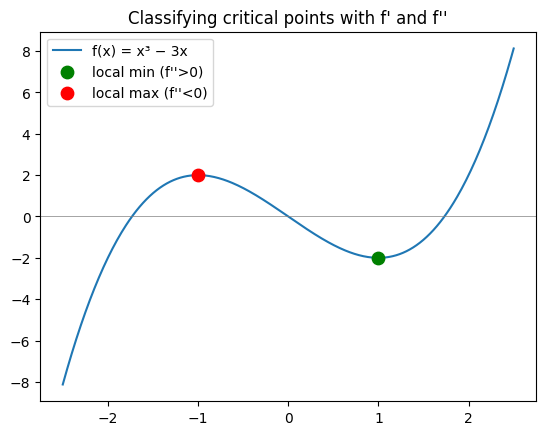

In [2]:
def f(x):   return x**3 - 3*x
def fp(x):  return 3*x**2 - 3
def fpp(x): return 6*x

def classify(fp, fpp, c, tol=1e-9):
    g, h = fp(c), fpp(c)
    if abs(g) > tol:
        return "not critical (fails 1st-order necessary)"
    if h > tol:
        return "strict local MIN (sufficient condition holds)"
    if h < -tol:
        return "local MAX (fails 2nd-order necessary)"
    return "inconclusive (necessary holds, sufficient fails)"

h = 1e-3
for c in [-1.0, 0.0, 1.0]:
    print(f"x={c:5.1f}  f'={fp(c):7.3f}  f''={fpp(c):6.2f}  "
          f"f(x-h)={f(c-h):.6f} f(x)={f(c):.6f} f(x+h)={f(c+h):.6f}")
    print("   ->", classify(fp, fpp, c))

x = np.linspace(-2.5, 2.5, 400)
plt.plot(x, f(x), label="f(x) = x³ − 3x")
plt.scatter([1], [f(1)], color="green", s=80, zorder=3, label="local min (f''>0)")
plt.scatter([-1], [f(-1)], color="red", s=80, zorder=3, label="local max (f''<0)")
plt.axhline(0, color="gray", lw=0.5)
plt.legend(); plt.title("Classifying critical points with f' and f''")
plt.show()

At x = 1 the output shows f′ = 0 and f″ = 6 > 0, and both neighbors f(1 ± h) are larger than f(1) = −2. That confirms the sufficient condition. At x = −1, f′ = 0 too, but f″ = −6, so it fails the necessary condition and is a maximum. This shows that f′ = 0 alone doesn't identify a minimizer. At x = 0, f′ ≠ 0, so 0 isn't even a candidate.

## 3.3.2 Convexity and Global Minimizers

A function f is convex if for all a, b and 0 ≤ t ≤ 1,
f(t·a + (1−t)·b) ≤ t·f(a) + (1−t)·f(b), so the graph lies below every chord.
For smooth f in one variable this is equivalent to f''(x) ≥ 0 everywhere.
Key fact: for a convex function, every local minimizer is a global minimizer.

min of g'' on grid: 2.0
min of q'' on grid: -7.9997
chord violations for g: 0
chord violations for q: 3857

g: critical point x = 1, g(1) = 2.0 -> global min
q: x = -1.4730, q(x) =  -5.4442, q''(x) =  18.037 -> local min
q: x =  0.1260, q(x) =   0.0627, q''(x) =  -7.809 -> local max
q: x =  1.3470, q(x) =  -2.6186, q''(x) =  13.773 -> local min


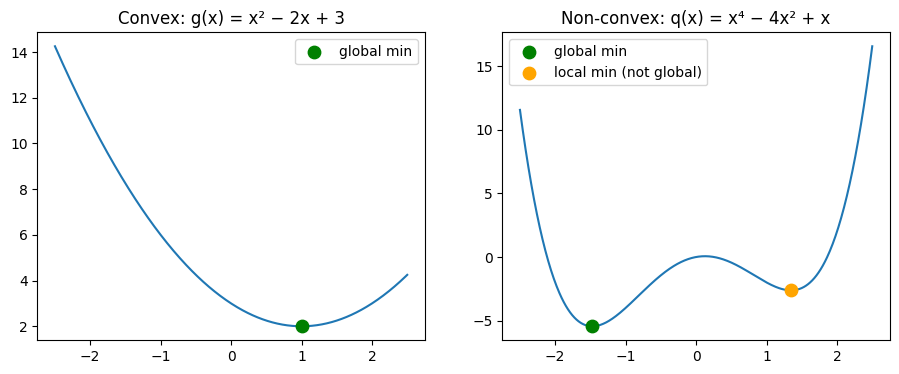

In [3]:
def g(x):   return x**2 - 2*x + 3
def gpp(x): return 2 + 0*x
def q(x):   return x**4 - 4*x**2 + x
def qpp(x): return 12*x**2 - 8

xs = np.linspace(-2.5, 2.5, 500)

# check the second derivative
print("min of g'' on grid:", gpp(xs).min())
print("min of q'' on grid:", round(qpp(xs).min(), 4))

# check the chord inequality at 10,000 random (a, b, t)
rng = np.random.default_rng(0)
def chord_violations(func, n=10000):
    a, b = rng.uniform(-2.5, 2.5, n), rng.uniform(-2.5, 2.5, n)
    t = rng.uniform(0, 1, n)
    return int(np.sum(func(t*a + (1-t)*b) > t*func(a) + (1-t)*func(b) + 1e-12))
print("chord violations for g:", chord_violations(g))
print("chord violations for q:", chord_violations(q))

# crit points
print("\ng: critical point x = 1, g(1) =", g(1.0), "-> global min")
roots = np.roots([4, 0, -8, 1])            # solves q'(x) = 4x^3 - 8x + 1 = 0
roots = np.sort(roots[np.isreal(roots)].real)
for r in roots:
    kind = "local min" if qpp(r) > 0 else "local max"
    print(f"q: x = {r:7.4f}, q(x) = {q(r):8.4f}, q''(x) = {qpp(r):7.3f} -> {kind}")

mins = [r for r in roots if qpp(r) > 0]
best = min(mins, key=q)

# plot
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(xs, g(xs))
axes[0].scatter([1], [g(1)], color="green", s=80, zorder=3, label="global min")
axes[0].set_title("Convex: g(x) = x² − 2x + 3"); axes[0].legend()

axes[1].plot(xs, q(xs))
for r in mins:
    color = "green" if r == best else "orange"
    label = "global min" if r == best else "local min (not global)"
    axes[1].scatter([r], [q(r)], color=color, s=80, zorder=3, label=label)
axes[1].set_title("Non-convex: q(x) = x⁴ − 4x² + x"); axes[1].legend()
plt.show()

The code tests convexity in two ways. First, it finds the smallest value of the second derivative on a grid. Second, it checks the chord inequality at 10,000 random points and counts how many times it fails. It then finds the critical points of each function, classifies them with the second derivative, and plots both functions with their minimizers marked.

For g, the second derivative is always 2 and there are 0 chord violations, so g is convex. Its only critical point, x = 1, is the global minimum with g(1) = 2. For q, the second derivative drops to −8 and many chord tests fail, so q is not convex. It has two local minima, near x ≈ −1.47 and x ≈ 1.35. The one at x ≈ 1.35 has a higher value, so it is a local minimum but not the global one.

# 3.3.3 Gradient Descent

Gradient descent updates x_{k+1} = x_k − α·f'(x_k), where α > 0 is the learning rate.
Each step moves opposite the derivative, which is the downhill direction.

For example, g(x) = x² − 2x + 3, g'(x) = 2x − 2, minimizer x* = 1.
Here x_{k+1} − 1 = (1 − 2α)(x_k − 1), so the error shrinks only if |1 − 2α| < 1, i.e. 0 < α < 1.

lr =  0.1: final x =    1.03459, g(x) =      2.00120, |g'(x)| = 6.92e-02, error factor |1-2lr| = 0.80
lr =  0.4: final x =    1.00000, g(x) =      2.00000, |g'(x)| = 6.31e-14, error factor |1-2lr| = 0.20
lr = 1.05: final x =   21.18250, g(x) =    409.33330, |g'(x)| = 4.04e+01, error factor |1-2lr| = 1.10

start = -0.5: final x = -1.4730, q(x) = -5.4442
start =  0.5: final x = 1.3470, q(x) = -2.6186


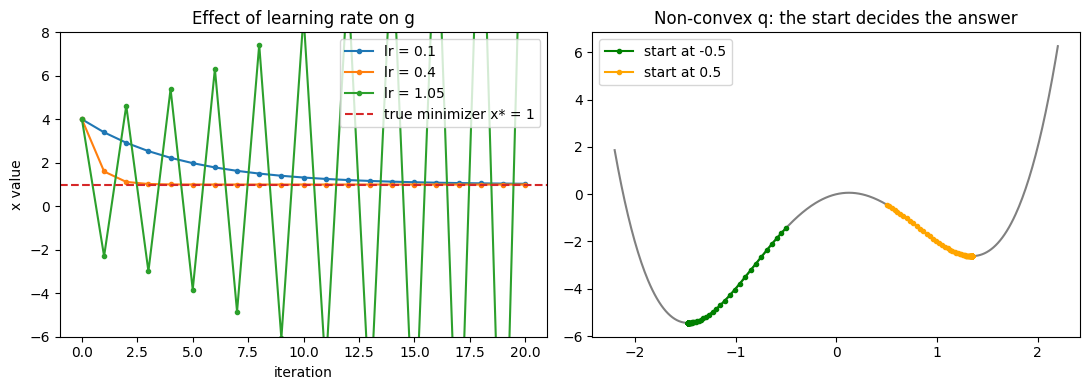

In [4]:
def g(x):      return x**2 - 2*x + 3
def grad_g(x): return 2*x - 2

def gradient_descent(grad, x0, lr, steps):
    path = [x0]
    for _ in range(steps):
        path.append(path[-1] - lr * grad(path[-1]))
    return np.array(path)

# Example 1: compare learning rates on a convex function
x0, steps = 4.0, 20
rates = [0.1, 0.4, 1.05]
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
for lr in rates:
    path = gradient_descent(grad_g, x0, lr, steps)
    print(f"lr = {lr:4}: final x = {path[-1]:10.5f}, g(x) = {g(path[-1]):12.5f}, "
          f"|g'(x)| = {abs(grad_g(path[-1])):.2e}, error factor |1-2lr| = {abs(1-2*lr):.2f}")
    plt.plot(path, marker="o", ms=3, label=f"lr = {lr}")
plt.axhline(1, color="tab:red", ls="--", label="true minimizer x* = 1")
plt.ylim(-6, 8); plt.xlabel("iteration"); plt.ylabel("x value")
plt.title("Effect of learning rate on g"); plt.legend()

# Example 2: non-convex function, two starting points
def q(x):      return x**4 - 4*x**2 + x
def grad_q(x): return 4*x**3 - 8*x + 1

print()
xs = np.linspace(-2.2, 2.2, 400)
plt.subplot(1, 2, 2)
plt.plot(xs, q(xs), color="gray")
for start, color in [(-0.5, "green"), (0.5, "orange")]:
    path = gradient_descent(grad_q, start, 0.01, 500)
    print(f"start = {start:4}: final x = {path[-1]:.4f}, q(x) = {q(path[-1]):.4f}")
    plt.plot(path, q(path), "o-", color=color, ms=3, label=f"start at {start}")
plt.title("Non-convex q: the start decides the answer"); plt.legend()
plt.tight_layout(); plt.show()

I run 20 steps of gradient descent on g(x) = x² − 2x + 3, starting at x = 4, with learning rates 0.1, 0.4 and 1.05. For each one, the code prints the final x, the function value, and the size of the derivative, and it plots the iterates. Second, I run gradient descent on q(x) = x⁴ − 4x² + x from x = −0.5 and x = 0.5 and plot the paths on the graph of q.

With α = 0.1, x gets close to 1 but slowly (about 1.035 after 20 steps), because the error only shrinks by a factor of 0.8 each step. With α = 0.4, the error shrinks by a factor of 0.2 each step, so x reaches 1 almost exactly and the derivative is essentially 0. With α = 1.05, the factor is 1.1 > 1, so each step overshoots and x moves farther away, ending around 21. On q, starting at −0.5 leads to the global minimum near x ≈ −1.47, but starting at 0.5 leads to the local minimum near x ≈ 1.35, which has a higher value.